# Customer Churn: Modeling

**Goal:** predict which customers will churn.

**Plan**
1. Load, clean and split the data (stratified **70 / 15 / 15**)
2. Train three models in a `for` loop: **Logistic Regression** (baseline), **Random Forest**, **XGBoost**
3. Compare them on the **validation** set using **Precision** and **Recall** (plus F1 and PR-AUC)
4. Pick the best model and evaluate it **once** on the **test** set
5. Inspect feature importances


## 1. Imports and settings


In [11]:
import sys
import os
from pathlib import Path

import pickle
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
)
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

sys.path.append(str(Path.cwd()))
sys.path.append(str(Path.cwd().parent))

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.preprocess import (
    DATA_PATH,
    TARGET,
    add_features,
    build_preprocessor,
    clean_data,
    split_data,
)

SEED = 42
MODELS_PATH = Path("models")

pd.set_option("display.max_columns", 50)
FIGURES_DIR = ROOT / 'reports' / 'figures'


## 2. Load, Clean, and Stratified Split (70 / 15 / 15)


In [12]:
raw_df = pd.read_csv(DATA_PATH)
print(f"Raw data shape: {raw_df.shape}")

clean_df = add_features(clean_data(raw_df))
print(f"Cleaned & feature-engineered data shape: {clean_df.shape}")

X_train, X_val, X_test, y_train, y_val, y_test = split_data(
    clean_df, train_size=0.70, val_size=0.15, test_size=0.15, seed=SEED
)

split_summary = pd.DataFrame([
    {"Split": "Train", "Samples": len(y_train), "Attritions": int(y_train.sum()), "Attrition Rate": float(y_train.mean())},
    {"Split": "Validation", "Samples": len(y_val), "Attritions": int(y_val.sum()), "Attrition Rate": float(y_val.mean())},
    {"Split": "Test", "Samples": len(y_test), "Attritions": int(y_test.sum()), "Attrition Rate": float(y_test.mean())},
])
display(split_summary)


Raw data shape: (3941, 11)
Cleaned & feature-engineered data shape: (3269, 15)


,Split,Samples,Attritions,Attrition Rate
0,Train,2288,373,0.163024
1,Validation,490,80,0.163265
2,Test,491,80,0.162933


## 3. Define Candidate Models & Class Imbalance Strategy


In [13]:
neg_count = int((y_train == 0).sum())
pos_count = int((y_train == 1).sum())
scale_pos_weight = neg_count / pos_count
print(f"Training Class Distribution: Retained (0) = {neg_count} | Attrited (1) = {pos_count}")
print(f"Computed scale_pos_weight for XGBoost = {scale_pos_weight:.2f}")

candidate_models = {
    "LogisticRegression": Pipeline(steps=[
        ("pre", build_preprocessor(scale=True)),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=SEED,
        )),
    ]),
    "RandomForest": Pipeline(steps=[
        ("pre", build_preprocessor(scale=False)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            n_jobs=-1,
            random_state=SEED,
        )),
    ]),
    "XGBoost": Pipeline(steps=[
        ("pre", build_preprocessor(scale=False)),
        ("model", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight,
            eval_metric="logloss",
            random_state=SEED,
            n_jobs=-1,
        )),
    ]),
}


Training Class Distribution: Retained (0) = 1915 | Attrited (1) = 373
Computed scale_pos_weight for XGBoost = 5.13


## 4. Train Models in a Loop & Compare on Validation Set


In [14]:
results = []
fitted = {}

for name, pipe in candidate_models.items():
    print(f"Training [{name}]...")
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    y_val_pred = pipe.predict(X_val)
    y_val_proba = pipe.predict_proba(X_val)[:, 1]

    metrics = {
        "model": name,
        "precision": precision_score(y_val, y_val_pred, zero_division=0),
        "recall": recall_score(y_val, y_val_pred, zero_division=0),
        "f1": f1_score(y_val, y_val_pred, zero_division=0),
        "pr_auc": average_precision_score(y_val, y_val_proba),
        "roc_auc": roc_auc_score(y_val, y_val_proba),
    }
    results.append(metrics)
    print(f"{name:20s} | precision={metrics['precision']:.3f} | recall={metrics['recall']:.3f} | f1={metrics['f1']:.3f} | pr_auc={metrics['pr_auc']:.3f} | roc_auc={metrics['roc_auc']:.3f}")


Training [LogisticRegression]...
LogisticRegression   | precision=0.468 | recall=0.900 | f1=0.615 | pr_auc=0.681 | roc_auc=0.921
Training [RandomForest]...
RandomForest         | precision=0.754 | recall=0.613 | f1=0.676 | pr_auc=0.780 | roc_auc=0.955
Training [XGBoost]...
XGBoost              | precision=0.676 | recall=0.887 | f1=0.768 | pr_auc=0.832 | roc_auc=0.962


## 5. Compare the models (validation set)

In [15]:
results_df = pd.DataFrame(results).sort_values("f1", ascending=False).reset_index(drop=True)
results_df.round(4)


,model,precision,recall,f1,pr_auc,roc_auc
0,XGBoost,0.6762,0.8875,0.7676,0.8317,0.9620
1,RandomForest,0.7538,0.6125,0.6759,0.7799,0.9545
2,LogisticRegression,0.4675,0.9000,0.6154,0.6809,0.9207


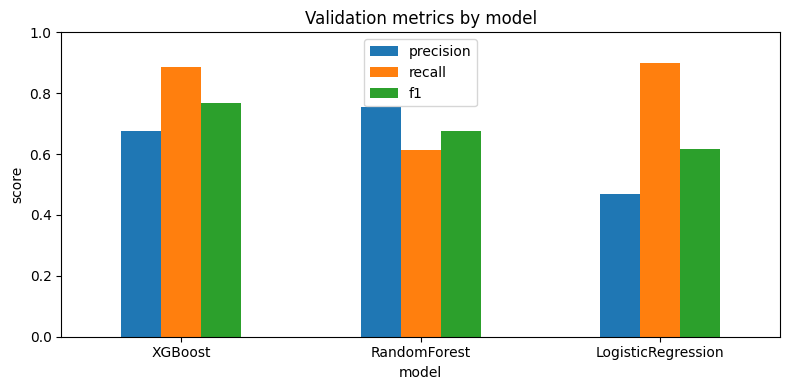

In [16]:
ax = results_df.set_index("model")[["precision", "recall", "f1"]].plot(
    kind="bar", figsize=(8, 4), rot=0, ylim=(0, 1)
)
ax.set_title("Validation metrics by model")
ax.set_ylabel("score")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_model_comparison_metrics.png", dpi=300, bbox_inches="tight")
plt.show()


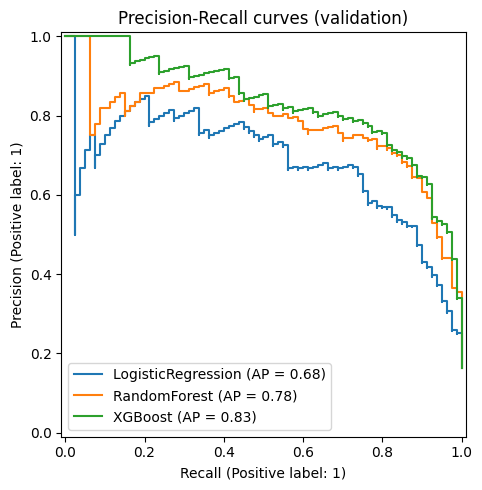

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in fitted.items():
    PrecisionRecallDisplay.from_estimator(pipe, X_val, y_val, name=name, ax=ax)
ax.set_title("Precision-Recall curves (validation)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_precision_recall_curves.png", dpi=300, bbox_inches="tight")
plt.show()


## 6. Select the best model


Best model: XGBoost


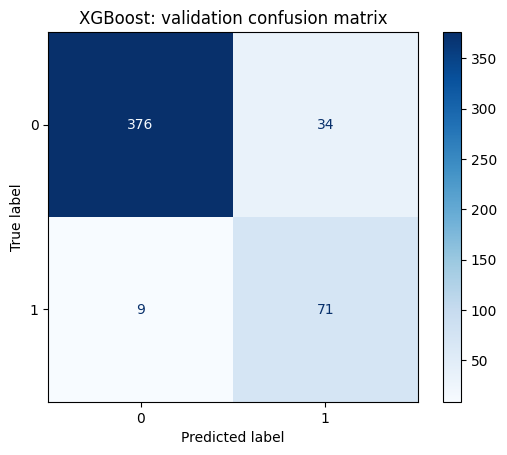

In [18]:
best_name = results_df.loc[0, "model"]
best_pipe = fitted[best_name]
print("Best model:", best_name)

ConfusionMatrixDisplay.from_estimator(best_pipe, X_val, y_val, cmap="Blues")
plt.title(f"{best_name}: validation confusion matrix")
plt.savefig(FIGURES_DIR / "12_validation_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


## 7. Final evaluation on the test set

              precision    recall  f1-score   support

           0      0.958     0.937     0.947       411
           1      0.708     0.787     0.746        80

    accuracy                          0.912       491
   macro avg      0.833     0.862     0.846       491
weighted avg      0.917     0.912     0.914       491



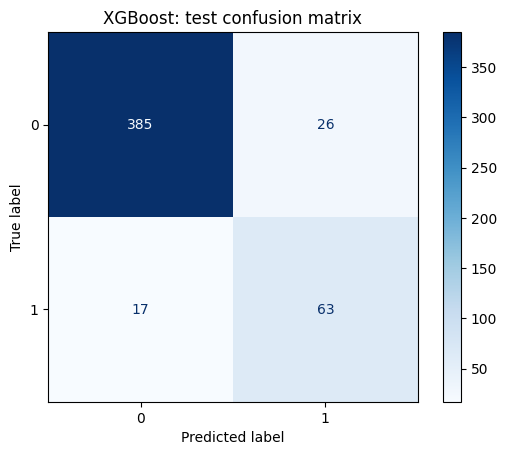

In [19]:
test_pred = best_pipe.predict(X_test)
print(classification_report(y_test, test_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, test_pred, cmap="Blues")
plt.title(f"{best_name}: test confusion matrix")
plt.savefig(FIGURES_DIR / "13_test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


## 8. Feature Importance


C:\Users\dxt\AppData\Local\Temp\ipykernel_8476\3263822125.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x='Importance', y='Feature', palette='mako', ax=ax)


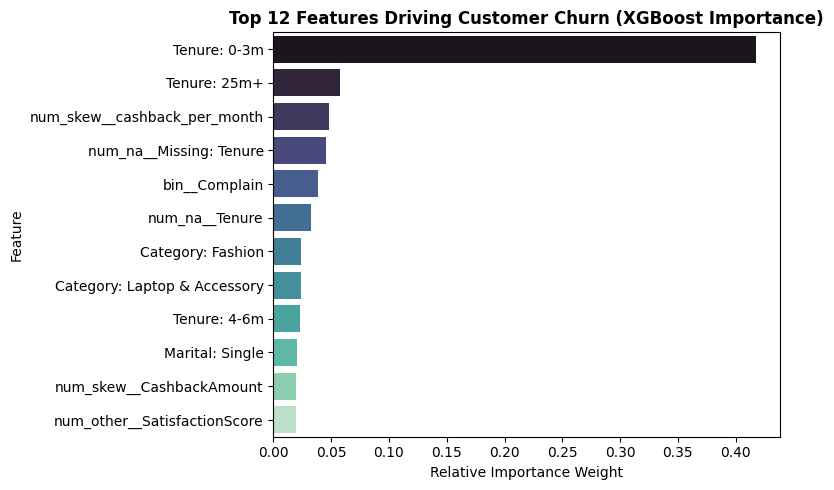

In [20]:
pre = best_pipe.named_steps['pre']
xgb_clf = best_pipe.named_steps['model']
raw_names = pre.get_feature_names_out()

clean_names = [
    n.replace('num__', '')
    .replace('cat__', '')
    .replace('PreferedOrderCat_', 'Category: ')
    .replace('MaritalStatus_', 'Marital: ')
    .replace('tenure_band_', 'Tenure: ')
    .replace('missingindicator_', 'Missing: ')
    for n in raw_names
]

fi_df = (
    pd.DataFrame({'Feature': clean_names, 'Importance': xgb_clf.feature_importances_})
    .sort_values('Importance', ascending=False)
    .head(12)
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=fi_df, x='Importance', y='Feature', palette='mako', ax=ax)
ax.set_title('Top 12 Features Driving Customer Churn (XGBoost Importance)', fontweight='bold')
ax.set_xlabel('Relative Importance Weight')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '14_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
